# 06 — Advanced Models (Week 7)
**Goal:** try **gradient boosting** (LightGBM and XGBoost), tune it lightly (depth, learning rate, number of trees), and compare test metrics against Week 6's best: **Random Forest, R² 0.883**.

Fixed from Week 6 so only the model changes: the data (`features_sfr.csv`), the full feature set D (Week 5 features + age & ratios + school district + nearby comps), and the split (train May 2025 – Apr 2026, test May 2026).

| What | Technique |
|---|---|
| Two boosting libraries | LightGBM (leaf-wise trees) and XGBoost (level-wise trees) |
| Choosing the number of trees | **Early stopping** on a validation month |
| Tuning XGBoost | **Grid search**: try every combination of a few values |
| Tuning LightGBM | **Optuna**: a search that learns from earlier trials which settings look promising (Bayesian optimisation, TPE) |
| Honest scores | All tuning on April 2026 (the practice month). May 2026 is scored **once**, at the end |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
import optuna
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)
optuna.logging.set_verbosity(optuna.logging.WARNING)

TARGET = "ClosePrice"
BASE_NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
                "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
ENGINEERED = ["Age", "BedBathRatio", "SqftPerBedroom"]
FEATURE_SET_D = dict(numeric=BASE_NUMERIC + ENGINEERED, encode_cols=["PostalCode", "SchoolDistrict"], comps=True)

## 1. Data and preprocessing
The helpers and `prepare()` below are copied unchanged from `05_feature_engineering.ipynb`.

In [2]:
SMOOTHING = 20     # sales a group needs before its own average outweighs the statewide one
K_COMPS = 10


def smoothed_price(train, test, col):
    """Each group's average log price, pulled toward the overall average when the group is small. Training rows only."""
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train[col]).agg(["mean", "count"])
    value = (stats["count"] * stats["mean"] + SMOOTHING * overall) / (stats["count"] + SMOOTHING)
    return train[col].map(value), test[col].map(value).fillna(overall)


def comps_price(train, test, k=K_COMPS):
    """Median log price-per-sq-ft of the k nearest TRAINING sales. A training home never counts itself."""
    to_radians = lambda d: np.radians(d[["Latitude", "Longitude"]].to_numpy())
    tree = BallTree(to_radians(train), metric="haversine")
    ppsf = np.log(train[TARGET] / train["LivingArea"]).to_numpy()

    _, idx_train = tree.query(to_radians(train), k=k + 1)
    own = idx_train == np.arange(len(train))[:, None]
    own[~own.any(axis=1), -1] = True           # self not returned (tied with an identical location): drop the farthest
    idx_train = idx_train[~own].reshape(len(train), k)

    _, idx_test = tree.query(to_radians(test), k=k)
    return np.median(ppsf[idx_train], axis=1), np.median(ppsf[idx_test], axis=1)

In [3]:
def prepare(train, test, numeric, encode_cols, comps=False):
    X_tr, X_te = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)

    # median fill + "was missing" flags
    medians = train[numeric].median()
    for col in numeric:
        if train[col].isna().any():
            X_tr[f"{col}_missing"] = train[col].isna().astype(int)
            X_te[f"{col}_missing"] = test[col].isna().astype(int)
        X_tr[col], X_te[col] = train[col].fillna(medians[col]), test[col].fillna(medians[col])
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        X_tr[col], X_te[col] = np.log1p(X_tr[col]), np.log1p(X_te[col])
    for col in BINARY:
        X_tr[col], X_te[col] = train[col], test[col]

    # location-price features, learned from training sales only
    scale_cols = list(numeric)
    for col in encode_cols:
        X_tr[f"{col}Price"], X_te[f"{col}Price"] = smoothed_price(train, test, col)
        scale_cols.append(f"{col}Price")
    if comps:
        X_tr["CompsPricePerSqft"], X_te["CompsPricePerSqft"] = comps_price(train, test)
        scale_cols.append("CompsPricePerSqft")

    # county one-hot: test gets exactly the training columns
    county_tr = pd.get_dummies(train["CountyOrParish"], prefix="CountyOrParish", dtype=int)
    county_te = pd.get_dummies(test["CountyOrParish"], prefix="CountyOrParish", dtype=int).reindex(
        columns=county_tr.columns, fill_value=0)
    X_tr, X_te = X_tr.join(county_tr), X_te.join(county_te)

    scaler = StandardScaler().fit(X_tr[scale_cols])
    X_tr[scale_cols], X_te[scale_cols] = scaler.transform(X_tr[scale_cols]), scaler.transform(X_te[scale_cols])
    return X_tr, X_te, np.log(train[TARGET]), test[TARGET]

Two splits:
* **Tuning:** train on the 12 months before April 2026 (Apr 2025 – Mar 2026) and validate on **April 2026**. Every tuning decision is made here.
* **Final:** train on May 2025 – Apr 2026 and test on **May 2026**, the same split as Weeks 4–6.

In [4]:
df = pd.read_csv("features_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
month = df["CloseDate"].dt.to_period("M")


def window(test_month, months_back=12):
    test_month = pd.Period(test_month, "M")
    return df[(month >= test_month - months_back) & (month < test_month)], df[month == test_month]


X_tune, X_val, y_tune, val_price = prepare(*window("2026-04"), **FEATURE_SET_D)
y_val = np.log(val_price)          # validation in log price, the scale the models predict and early stopping watches
X_train, X_test, y_train, y_test = prepare(*window("2026-05"), **FEATURE_SET_D)   # y_test stays in dollars
assert (df.loc[X_train.index, "Split"] == "train").all() and (df.loc[X_test.index, "Split"] == "test").all()

print(f"Tuning:  {len(X_tune):,} train  -> {len(X_val):,} validation (Apr 2026)")
print(f"Final:   {len(X_train):,} train  -> {len(X_test):,} test (May 2026), {X_train.shape[1]} features")


def dollars_r2(y_log_true, pred_log):
    return r2_score(np.exp(y_log_true), np.exp(pred_log))

Tuning:  106,532 train  -> 11,997 validation (Apr 2026)
Final:   106,696 train  -> 11,991 test (May 2026), 83 features


## 2. How gradient boosting differs from a random forest
* **Random forest:** many deep trees built **independently**, then averaged. Averaging cancels out noise.
* **Gradient boosting:** small trees built **one after another**. Each new tree is trained on the errors the previous trees still make, so the model keeps correcting itself.

The three settings the plan asks us to tune:

| Setting | What it controls | Too low | Too high |
|---|---|---|---|
| `learning_rate` | How much each new tree is allowed to correct | Needs thousands of trees | Overshoots and overfits |
| `n_estimators` | How many trees in the sequence | Stops before learning enough | Starts fitting noise |
| depth (`max_depth` / LightGBM's `num_leaves`) | How complex each tree is | Misses interactions | Each tree memorizes |

`learning_rate` and `n_estimators` trade off: halve one and you need about twice the other. So we don't grid-search `n_estimators`; we let **early stopping** pick it.

## 3. Early stopping: picking the number of trees
Keep adding trees while watching the validation month's error. When it hasn't improved for 50 trees, stop and keep the best point.

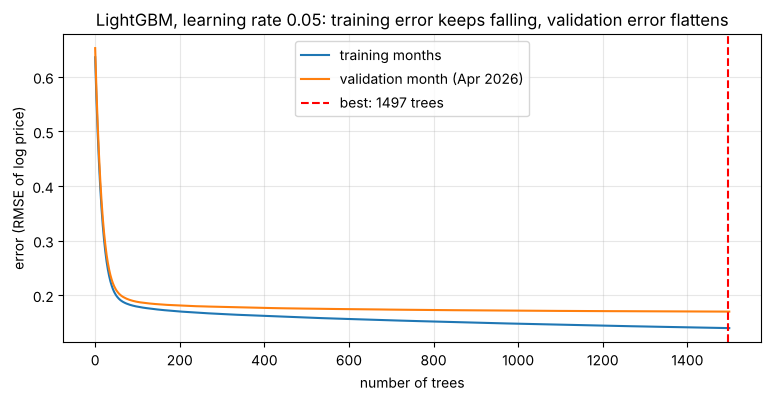

In [5]:
curves = {}
demo = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, verbose=-1, n_jobs=-1, random_state=0)
demo.fit(X_tune, y_tune, eval_set=[(X_tune, y_tune), (X_val, y_val)], eval_names=["train", "validation"],
         callbacks=[lgb.record_evaluation(curves)])

val_err = np.sqrt(curves["validation"]["l2"])
best_n = int(np.argmin(val_err)) + 1
plt.figure(figsize=(9, 4))
plt.plot(np.sqrt(curves["train"]["l2"]), label="training months")
plt.plot(val_err, label="validation month (Apr 2026)")
plt.axvline(best_n, color="red", ls="--", label=f"best: {best_n} trees")
plt.xlabel("number of trees"); plt.ylabel("error (RMSE of log price)")
plt.title("LightGBM, learning rate 0.05: training error keeps falling, validation error flattens")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Training error falls forever because the model keeps fitting the training homes more closely. Validation error stops improving after a while. Past that point, extra trees only memorize, which is why the number of trees is chosen on the validation month.

## 4. Tuning XGBoost with a grid search
Try every combination of `max_depth` × `learning_rate`, each with early stopping to choose `n_estimators`. That's 9 fits. Simple and easy to explain, but the number of fits multiplies with every setting you add.

In [6]:
grid_rows = []
for depth in [4, 6, 8]:
    for lr in [0.05, 0.1, 0.3]:
        model = xgb.XGBRegressor(n_estimators=2000, learning_rate=lr, max_depth=depth, subsample=0.8,
                                 colsample_bytree=0.8, tree_method="hist", early_stopping_rounds=50,
                                 n_jobs=-1, random_state=0)
        model.fit(X_tune, y_tune, eval_set=[(X_val, y_val)], verbose=False)
        grid_rows.append({"max_depth": depth, "learning_rate": lr, "best_n_trees": model.best_iteration + 1,
                          "val_R2": dollars_r2(y_val, model.predict(X_val))})

grid = pd.DataFrame(grid_rows)
grid.pivot(index="max_depth", columns="learning_rate", values="val_R2")

learning_rate,0.050,0.100,0.300
max_depth,,,
4,0.876,0.882,0.874
6,0.883,0.884,0.868
8,0.882,0.882,0.874


In [7]:
best_xgb = grid.loc[grid["val_R2"].idxmax()]
XGB_PARAMS = dict(max_depth=int(best_xgb["max_depth"]), learning_rate=best_xgb["learning_rate"],
                  n_estimators=int(best_xgb["best_n_trees"]), subsample=0.8, colsample_bytree=0.8)
print("XGBoost chosen on April:", XGB_PARAMS, f"(validation R² {best_xgb['val_R2']:.3f})")

XGBoost chosen on April: {'max_depth': 6, 'learning_rate': np.float64(0.1), 'n_estimators': 1288, 'subsample': 0.8, 'colsample_bytree': 0.8} (validation R² 0.884)


## 5. Tuning LightGBM with Optuna
A grid wastes most of its fits on obviously bad combinations, and it gets expensive fast: 6 settings × 4 values each = 4,096 fits. **Optuna** runs one trial at a time and uses the results so far to choose the next settings to try, concentrating on the promising region.

Settings searched (15 trials, each with early stopping; more trials would help a little, at more run time):
* `learning_rate`, and `num_leaves` (LightGBM's version of depth: it grows trees leaf by leaf, so it limits leaves instead of levels)
* `min_child_samples`: smallest number of homes allowed in a leaf
* `subsample`, `colsample_bytree`: train each tree on a random share of homes and features (the same trick that makes random forests work)
* `reg_lambda`: a penalty that keeps leaf values from getting extreme

In [8]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )
    model = lgb.LGBMRegressor(n_estimators=2000, verbose=-1, n_jobs=-1, random_state=0, **params)
    model.fit(X_tune, y_tune, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    trial.set_user_attr("best_n_trees", model.best_iteration_)
    return dollars_r2(y_val, model.predict(X_val))


start = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=15)
print(f"15 trials in {time.time() - start:.0f} s, best validation R² {study.best_value:.3f}")

15 trials in 180 s, best validation R² 0.887


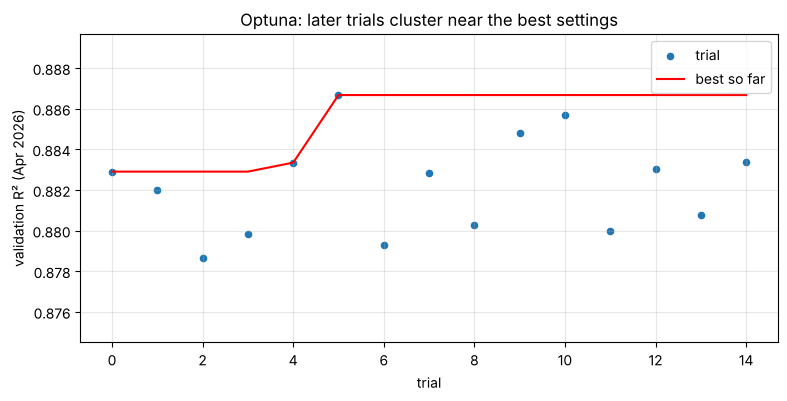

,chosen on April
learning_rate,0.050
num_leaves,134.000
min_child_samples,25.000
subsample,0.784
colsample_bytree,0.313
reg_lambda,0.295
subsample_freq,1.000
n_estimators,"1,054.000"


In [9]:
trials = study.trials_dataframe()
plt.figure(figsize=(9, 4))
plt.scatter(trials["number"], trials["value"], s=20, label="trial")
plt.plot(trials["number"], trials["value"].cummax(), color="red", label="best so far")
plt.ylim(trials["value"].quantile(0.1) - 0.005, trials["value"].max() + 0.003)
plt.xlabel("trial"); plt.ylabel("validation R² (Apr 2026)")
plt.title("Optuna: later trials cluster near the best settings")
plt.legend(); plt.grid(alpha=0.3); plt.show()

LGB_PARAMS = dict(study.best_params, subsample_freq=1,
                  n_estimators=study.best_trial.user_attrs["best_n_trees"])
pd.Series(LGB_PARAMS).to_frame("chosen on April")

## 6. Final test on May 2026
Each model is re-trained on May 2025 – Apr 2026 with the settings chosen on April (including the number of trees from early stopping), then scored **once** on May. Week 6's Linear Regression and Random Forest are re-run on the same features for reference.

In [10]:
models = {
    "Linear Regression (Week 6)": LinearRegression(),
    "Random Forest (Week 6)": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.33,
                                                    n_jobs=-1, random_state=0),
    "XGBoost, default settings": xgb.XGBRegressor(tree_method="hist", n_jobs=-1, random_state=0),
    "XGBoost, grid-tuned": xgb.XGBRegressor(tree_method="hist", n_jobs=-1, random_state=0, **XGB_PARAMS),
    "LightGBM, default settings": lgb.LGBMRegressor(verbose=-1, n_jobs=-1, random_state=0),
    "LightGBM, Optuna-tuned": lgb.LGBMRegressor(verbose=-1, n_jobs=-1, random_state=0, **LGB_PARAMS),
}

rows, predictions = [], {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    seconds = time.time() - start
    pred = np.exp(model.predict(X_test))
    predictions[name] = pred
    rows.append({"model": name, "test_R2": r2_score(y_test, pred),
                 "median_pct_error": np.median(np.abs(pred - y_test) / y_test), "fit_seconds": seconds})

final = pd.DataFrame(rows).set_index("model")
final["R2_vs_RF"] = final["test_R2"] - final.loc["Random Forest (Week 6)", "test_R2"]
final

,test_R2,median_pct_error,fit_seconds,R2_vs_RF
model,,,,
Linear Regression (Week 6),0.866,0.098,1.195,-0.017
Random Forest (Week 6),0.883,0.080,21.088,0.000
"XGBoost, default settings",0.887,0.086,1.463,0.005
"XGBoost, grid-tuned",0.886,0.079,11.579,0.004
"LightGBM, default settings",0.884,0.089,0.894,0.001
"LightGBM, Optuna-tuned",0.885,0.078,10.617,0.002


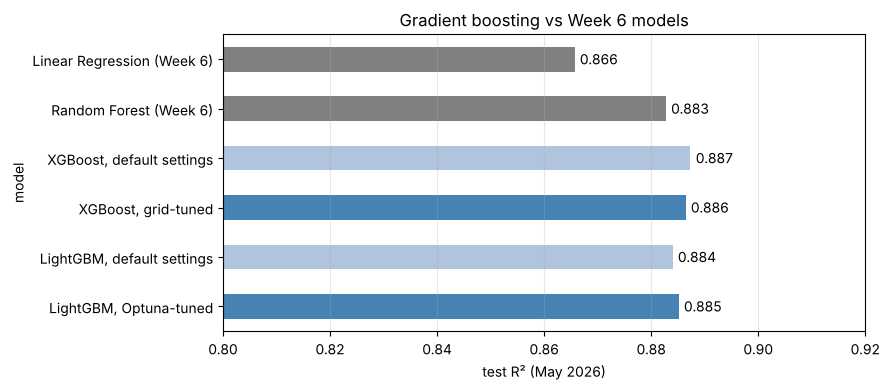

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
final["test_R2"].plot.barh(ax=ax, color=["gray", "gray", "lightsteelblue", "steelblue", "lightsteelblue", "steelblue"])
ax.set_xlim(0.8, 0.92); ax.set_xlabel("test R² (May 2026)"); ax.invert_yaxis()
for i, v in enumerate(final["test_R2"]):
    ax.text(v + 0.001, i, f"{v:.3f}", va="center")
ax.set_title("Gradient boosting vs Week 6 models"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

### Typical error by price band

In [12]:
bands = pd.qcut(y_test, 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "priciest 20%"])
best_name = final["test_R2"].idxmax()
show = ["Random Forest (Week 6)", best_name]
pd.DataFrame({name: (np.abs(predictions[name] - y_test) / y_test).groupby(bands, observed=True).median()
              for name in show}).rename_axis("price band")

,Random Forest (Week 6),"XGBoost, default settings"
price band,,
cheapest 20%,0.073,0.077
20–40%,0.058,0.067
40–60%,0.073,0.079
60–80%,0.089,0.095
priciest 20%,0.120,0.120


**Reading the results**

| Model | Test R² | Typical (median) error | Fit time |
|---|---|---|---|
| Random Forest (Week 6) | 0.883 | 8.0% | 21 s |
| XGBoost, default → grid-tuned | 0.887 → 0.886 | 8.6% → **7.9%** | 1 s → 12 s |
| LightGBM, default → Optuna-tuned | 0.884 → 0.885 | 8.9% → **7.8%** | 1 s → 11 s |

* **Boosting edges out the Random Forest, but only just.** All four boosted models land at R² 0.884–0.887, a gain of at most +0.004. On one test month that's within noise. The honest conclusion is that **we're near the ceiling of what these features can explain**; the big jumps came from features in Week 6 (0.853 → 0.883), not from switching models.
* **Tuning didn't raise R², it cut the typical error.** Default boosting has slightly *higher* R² but worse typical error (8.6–8.9%). R² is in dollars, so it's dominated by a few expensive homes. Tuning traded a hair of that for better accuracy on everyday homes: **the Optuna-tuned LightGBM has the lowest typical error of any model so far, 7.8%.**
* **The grid confirms the theory.** A learning rate of 0.3 is worst at every depth (it overshoots); 0.05–0.1 at depth 6 is best. Early stopping picked 1,288 trees for XGBoost and 1,054 for LightGBM, so nobody had to guess.
* **Optuna found a better setting in fewer tries:** 15 trials reached validation R² 0.887 vs the grid's best 0.884 from 9. One interesting choice: `colsample_bytree ≈ 0.31`, so each tree sees only a third of the features. Our location features (ZIP price, district price, comps, coordinates) overlap heavily; forcing trees to use different subsets stops them all leaning on the same one. That's the same idea as the Random Forest's `max_features=0.33`.
* **Expensive homes are still the weak spot:** about 12% typical error for the priciest 20%, for every model. That's a data problem (views, finishes, lot quality aren't in the data), not a model problem.

## Summary
* **Models:** XGBoost and LightGBM on Week 6's best feature set, same split as Weeks 4–6.
* **Tuning (all on April 2026, May untouched):** early stopping chose the number of trees; XGBoost via a 9-fit grid (depth × learning rate → depth 6, learning rate 0.1); LightGBM via 15 Optuna trials over 6 settings (learning rate 0.05, 134 leaves, ⅓ of features per tree).
* **Result (May 2026):** all boosted models reach R² ≈ 0.885 (vs 0.883 Random Forest). **Best overall: LightGBM, Optuna-tuned**: R² 0.885, **lowest typical error at 7.8%**, and half the Random Forest's training time. It's the candidate model for Weeks 8–9.
* **Takeaway:** model choice now matters less than features. Remaining error is concentrated in luxury homes.
* **Next (Week 8):** report MAPE and median APE, and break errors down by price band and region.